# Week 7c: Transformer vs scikit-learn

**The question:** your Week 2 categorizer is 96% accurate. Would a fine-tuned transformer be better, and is it worth it?

Three contenders, trained on exactly the same rows:
1. `tfidf_logreg`: your Week 2 model (character n-grams + logistic regression)
2. `minilm_logreg`: a pretrained sentence model turns each description into 384 numbers (no fine-tuning), then logistic regression
3. `distilbert`: a pretrained transformer, **fine-tuned** on your data

Three test sets: **seen** merchants (the usual random split), **unseen** merchants (held out completely), and **new** real Philippine merchants.

Everything here ends up in `blog/results.json` and `blog/figures/`, and your blog post quotes it. Spec: `docs/superpowers/specs/2026-10-23-deep-learning-design.md`

## Setup (given)

In [1]:
import importlib.util
import json
import statistics
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import make_pipeline
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments

sys.path.insert(0, '../service')
from clean import clean_description

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
MODELS = ['tfidf_logreg', 'minilm_logreg', 'distilbert']

df = pd.read_csv('../data/fake_transactions.csv')
df['Clean'] = df['Description'].fillna('').str.strip().apply(clean_description)
data = df[df['Clean'] != ''].reset_index(drop=True)

# One label order for everything (DistilBERT predicts numbers; these turn them back into names)
LABELS = sorted(data['Category'].unique())
LABEL2ID = {c: i for i, c in enumerate(LABELS)}
ID2LABEL = {i: c for c, i in LABEL2ID.items()}

new = pd.read_csv('../datasets/new_merchants.csv').rename(columns={'category': 'Category'})
new['Clean'] = new['description'].apply(clean_description)
assert set(new['Category']) <= set(LABELS), set(new['Category']) - set(LABELS)
print(len(data), 'fake rows,', len(new), 'new merchants,', len(LABELS), 'categories | device:', DEVICE)

W1023 23:42:20.158000 17656 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


1378 fake rows, 44 new merchants, 11 categories | device: cuda


### Merchant key (given)
Each fake description comes from a merchant in the generator (`JOLLIBEE*4821`, `jollibee makati` → **jollibee**). Matching the generator's merchant names inside the cleaned text recovers it, so the unseen split can hold out *every spelling* of a merchant.

In [2]:
spec = importlib.util.spec_from_file_location('gen', '../scripts/generate_fake_data.py')
gen = importlib.util.module_from_spec(spec); spec.loader.exec_module(gen)
NAMES = [m for merchants, *_ in gen.EXPENSES.values() for m in merchants] + [b[0] for b in gen.BILLS] \
        + ['Payroll', 'Upwork', 'Client payment', 'Fiverr', 'Gift', 'Refund', 'Sold item']
squash = lambda text: clean_description(text).replace(' ', '')   # 'MAX'SRESTAURANT*12' and "Max's Restaurant" match
KEYS = sorted({squash(n) for n in NAMES}, key=len, reverse=True)   # longest first: 'grabfood' before 'grab'

def merchant_of(text):
    s = squash(text)
    return next((k for k in KEYS if k in s), None)

data['Merchant'] = data['Description'].apply(merchant_of)
for d in new['description']:
    assert merchant_of(d) is None, f'{d!r} is not new: it contains a fake-data merchant'
print(data['Merchant'].isna().sum(), 'rows without a merchant;', data['Merchant'].nunique(), 'merchants')

0 rows without a merchant; 72 merchants


### The three test sets (given)

In [3]:
seen_train, seen_test = train_test_split(data, test_size=0.2, stratify=data['Category'], random_state=42)

grouped = data.dropna(subset=['Merchant'])
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(grouped, groups=grouped['Merchant']))
unseen_train, unseen_test = grouped.iloc[train_idx], grouped.iloc[test_idx]
assert not set(unseen_train['Merchant']) & set(unseen_test['Merchant']), 'a merchant is on both sides'

print(f'seen:   {len(seen_train)} train / {len(seen_test)} test')
print(f'unseen: {len(unseen_train)} train / {len(unseen_test)} test, held-out merchants: {sorted(unseen_test["Merchant"].unique())}')
print('categories never seen in unseen training:', set(LABELS) - set(unseen_train['Category']))

seen:   1102 train / 276 test
unseen: 1081 train / 297 test, held-out merchants: ['-eleven', 'ayalamallscinema', "bo'scoffee", 'chowking', 'clientpayment', 'coffeeproject', 'foodpanda', 'landers', 'lugaw', 'maynilad', 'pldthomefiber', 'puregold', 'rosepharmacy', 'shell', 'steam']
categories never seen in unseen training: set()


**Think:** look at the held-out merchants and the last line. Is any category missing from the unseen training data? What can **no** model do then, however clever? 

**Your answer:** No category is missing: the last line prints `set()`, so even with these 15 merchants held out, all 11 categories still have training rows from other merchants (e.g. Coffee & Snacks still has other coffee shops after Bo's Coffee and Coffee Project are removed). That check matters because if a category had no training rows at all, no model could ever predict it, however clever: a classifier can only choose among the labels it was trained on, so every test row of that category would be wrong whatever the architecture. The fix would be in the data (keep at least one merchant of each category in training), not in the model.

### Helpers (given)

In [7]:
def score(y_true, y_pred):
    assert set(y_pred) <= set(LABELS), 'predictions must be category names'
    return {'accuracy': round(accuracy_score(y_true, y_pred), 4),
            'macro_f1': round(f1_score(y_true, y_pred, average='macro', labels=sorted(set(y_true)), zero_division=0), 4)}

def latency_ms(predict_one, texts, warmup=20, runs=200):
    """Median milliseconds per single prediction, on the CPU with one thread, the same for every model."""
    threads = torch.get_num_threads(); torch.set_num_threads(1)
    try:
        for t in texts[:warmup]:
            predict_one(t)
        times = []
        for i in range(runs):
            start = time.perf_counter(); predict_one(texts[i % len(texts)]); times.append(time.perf_counter() - start)
        return round(statistics.median(times) * 1000, 3)
    finally:
        torch.set_num_threads(threads)

def size_mb(path):
    p = Path(path)
    files = [p] if p.is_file() else [f for f in p.rglob('*') if f.is_file()]
    return round(sum(f.stat().st_size for f in files) / 1e6, 2)

sample_texts = list(seen_test['Clean'])

---
## 1. The three models
Each `fit_…(texts, labels)` returns `(model, predict)`, where `predict(texts)` returns a **list of category names**.

**`fit_tfidf`:** your Week 2 pipeline: `make_pipeline(TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4)), LogisticRegression(max_iter=1000))`.

In [8]:
# TODO
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

def fit_tfidf(texts, labels):
    model = make_pipeline(
        TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4)),
        LogisticRegression(max_iter=1000),
    ).fit(list(texts), list(labels))

    def predict(texts):
        return list(model.predict(list(texts)))

    return model, predict

# Quick check
_m, _p = fit_tfidf(seen_train['Clean'], seen_train['Category'])
print(score(seen_test['Category'], _p(seen_test['Clean'])))

{'accuracy': 0.971, 'macro_f1': 0.7919}


**`fit_minilm`:** load `encoder = SentenceTransformer('all-MiniLM-L6-v2', device=DEVICE)` **once** (outside the function). `encoder.encode(texts)` gives a 384-number vector per description; fit `LogisticRegression(max_iter=2000)` on those. The encoder is never trained here: it only *reads*.

In [9]:
# TODO
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer('all-MiniLM-L6-v2', device=DEVICE)   # loaded once, never trained

def fit_minilm(texts, labels):
    X = encoder.encode(list(texts))                      # (n, 384) sentence vectors
    clf = LogisticRegression(max_iter=2000).fit(X, list(labels))

    def predict(texts):
        return list(clf.predict(encoder.encode(list(texts))))

    return clf, predict

# Quick check
_m, _p = fit_minilm(seen_train['Clean'], seen_train['Category'])
print(score(seen_test['Category'], _p(seen_test['Clean'])))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

{'accuracy': 0.9783, 'macro_f1': 0.8966}


**`fit_distilbert(texts, labels, out_dir)`:** fine-tuning.
- `tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')` (once)
- an `encode(texts, labels)` helper that tokenizes with `truncation=True, max_length=32, padding='max_length'` and returns a list of dicts, adding `'labels': LABEL2ID[label]`
- `AutoModelForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID)`
- `TrainingArguments(output_dir=out_dir, num_train_epochs=3, learning_rate=5e-5, per_device_train_batch_size=32, fp16=torch.cuda.is_available(), seed=42, save_strategy='no', report_to='none')`, then `Trainer(...).train()`
- `predict` tokenizes a batch (`return_tensors='pt'`, moved to `model.device`), takes `logits.argmax(-1)` and maps through `ID2LABEL`. Wrap it in `torch.no_grad()`.

**Think:** the new top layer (11 outputs) starts random, but every other layer starts from what DistilBERT learned reading Wikipedia and books. Why might that help with merchants it has never seen?

**Your answer:** A model trained from scratch only knows the strings in our ~1,100 training rows, so a merchant it has never seen is just unfamiliar characters. DistilBERT's lower layers already learned from Wikipedia and books how words and word pieces are used, so they may already "know" that "pharmacy", "coffee", "cinema", "pizza" or even a brand like "Shell" or "Steam" belongs with certain kinds of things. Fine-tuning only has to connect that existing knowledge to our 11 categories through the new top layer, so a new merchant whose name contains familiar words can land near similar merchants it did train on, e.g. "rose pharmacy" near other pharmacies → Healthcare.

In [10]:
# TODO
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)

tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')   # once

def encode(texts, labels):
    enc = tokenizer(list(texts), truncation=True, max_length=32, padding='max_length')
    return [{'input_ids': enc['input_ids'][i],
             'attention_mask': enc['attention_mask'][i],
             'labels': LABEL2ID[lab]}
            for i, lab in enumerate(labels)]

def fit_distilbert(texts, labels, out_dir):
    model = AutoModelForSequenceClassification.from_pretrained(
        'distilbert-base-uncased', num_labels=len(LABELS),
        id2label=ID2LABEL, label2id=LABEL2ID)

    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=3, learning_rate=5e-5,
        per_device_train_batch_size=32, fp16=torch.cuda.is_available(),
        seed=42, save_strategy='no', report_to='none')

    Trainer(model=model, args=args, train_dataset=encode(texts, list(labels))).train()
    model.eval()                                   # dropout off for predictions

    def predict(texts, batch=128):
        texts, out = list(texts), []
        with torch.no_grad():
            for i in range(0, len(texts), batch):
                enc = tokenizer(texts[i:i + batch], truncation=True, max_length=32,
                                padding=True, return_tensors='pt').to(model.device)
                out += [ID2LABEL[j] for j in model(**enc).logits.argmax(-1).tolist()]
        return out

    return model, predict

---
## 2. Train and score
For each experiment, train all three models on its training part and score them:
- **seen**: train on `seen_train`, score on `seen_test`
- **unseen**: train on `unseen_train`, score on `unseen_test` **and** on `new` (those models have never seen any of those merchants)

Keep `predictions[(model, test_set)]`, `fitted[(model, experiment)] = (obj, predict)` and the training time of each model in the **seen** experiment as `train_s[model]` (seconds). Print `score(...)` as you go. DistilBERT takes a few minutes per experiment on your GPU.

In [11]:
# TODO
predictions = {}   # (model, test set) -> list of predicted labels
fitted = {}        # (model, experiment) -> (object, predict)
train_s = {}       # model -> training seconds (seen experiment)

experiments = {
    'seen':   (seen_train,   {'seen': seen_test}),
    'unseen': (unseen_train, {'unseen': unseen_test, 'new': new}),
}

for exp, (train_part, tests) in experiments.items():
    models = [
        ('tfidf_logreg',  fit_tfidf),
        ('minilm_logreg', fit_minilm),
        ('distilbert',    lambda t, l, e=exp: fit_distilbert(t, l, f'../models/p5_distilbert_{e}')),
    ]
    for name, fit in models:
        start = time.perf_counter()
        obj, predict = fit(train_part['Clean'], train_part['Category'])
        if exp == 'seen':
            train_s[name] = round(time.perf_counter() - start, 1)
        fitted[(name, exp)] = (obj, predict)

        for test_name, test_part in tests.items():
            predictions[(name, test_name)] = predict(test_part['Clean'])
            print(f'{name:14s} {test_name:7s}', score(test_part['Category'], predictions[(name, test_name)]))

print('\ntraining seconds (seen):', train_s)

tfidf_logreg   seen    {'accuracy': 0.971, 'macro_f1': 0.7919}
minilm_logreg  seen    {'accuracy': 0.9783, 'macro_f1': 0.8966}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss


distilbert     seen    {'accuracy': 0.9746, 'macro_f1': 0.7956}
tfidf_logreg   unseen  {'accuracy': 0.6296, 'macro_f1': 0.3336}
tfidf_logreg   new     {'accuracy': 0.25, 'macro_f1': 0.1613}
minilm_logreg  unseen  {'accuracy': 0.4949, 'macro_f1': 0.2264}
minilm_logreg  new     {'accuracy': 0.3409, 'macro_f1': 0.2183}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss


distilbert     unseen  {'accuracy': 0.2559, 'macro_f1': 0.1777}
distilbert     new     {'accuracy': 0.2727, 'macro_f1': 0.1816}

training seconds (seen): {'tfidf_logreg': 0.1, 'minilm_logreg': 0.9, 'distilbert': 6.8}


---
## 3. Size and speed
**Size:** save each seen-experiment model under `../models/` (`joblib.dump` for scikit-learn; `encoder.save(...)` and `model.save_pretrained(...)` for the others) and measure it with `size_mb`. MiniLM's size is the encoder folder **plus** its logistic regression. Save a dict `sizes`.

In [12]:
# TODO
MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(exist_ok=True)

# TF-IDF + logistic regression: one pipeline file
tfidf_path = MODELS_DIR / 'p5_tfidf_logreg.joblib'
joblib.dump(fitted[('tfidf_logreg', 'seen')][0], tfidf_path)

# MiniLM: the encoder folder + its logistic regression
minilm_dir = MODELS_DIR / 'p5_minilm_encoder'
minilm_clf = MODELS_DIR / 'p5_minilm_logreg.joblib'
encoder.save(str(minilm_dir))
joblib.dump(fitted[('minilm_logreg', 'seen')][0], minilm_clf)

# DistilBERT: the fine-tuned model folder (plus the tokenizer the app would need)
distil_dir = MODELS_DIR / 'p5_distilbert_seen_model'
fitted[('distilbert', 'seen')][0].save_pretrained(distil_dir)
tokenizer.save_pretrained(distil_dir)

sizes = {
    'tfidf_logreg':  size_mb(tfidf_path),
    'minilm_logreg': round(size_mb(minilm_dir) + size_mb(minilm_clf), 2),
    'distilbert':    size_mb(distil_dir),
}
print(sizes)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'tfidf_logreg': 0.14, 'minilm_logreg': 91.61, 'distilbert': 268.57}


**Speed:** a server categorizes **one** description per request, usually on a CPU. Time each model with `latency_ms(predict_one, sample_texts)`: load CPU copies (`SentenceTransformer(path, device='cpu')`, `AutoModelForSequenceClassification.from_pretrained(path)`), and write a `predict_one(text)` for each. Save a dict `latency`.

In [13]:
# TODO
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# TF-IDF: the saved pipeline (already CPU-only)
tfidf_cpu = joblib.load(tfidf_path)
def tfidf_one(text):
    return tfidf_cpu.predict([text])[0]

# MiniLM: encoder on the CPU + its logistic regression
encoder_cpu = SentenceTransformer(str(minilm_dir), device='cpu')
minilm_clf_cpu = joblib.load(minilm_clf)
def minilm_one(text):
    return minilm_clf_cpu.predict(encoder_cpu.encode([text]))[0]

# DistilBERT: fine-tuned model loaded on the CPU
distil_tok = AutoTokenizer.from_pretrained(distil_dir)
distil_cpu = AutoModelForSequenceClassification.from_pretrained(distil_dir).eval()
@torch.no_grad()
def distilbert_one(text):
    enc = distil_tok([text], truncation=True, max_length=32, return_tensors='pt')
    return ID2LABEL[int(distil_cpu(**enc).logits.argmax(-1))]

# Sanity: the CPU copies give the same answers as the trained models
for name, one in [('tfidf_logreg', tfidf_one), ('minilm_logreg', minilm_one), ('distilbert', distilbert_one)]:
    same = sum(one(t) == p for t, p in zip(sample_texts[:50], predictions[(name, 'seen')][:50]))
    print(f'{name:14s} matches the trained model on {same}/50')

latency = {
    'tfidf_logreg':  latency_ms(tfidf_one, sample_texts),
    'minilm_logreg': latency_ms(minilm_one, sample_texts),
    'distilbert':    latency_ms(distilbert_one, sample_texts),
}
print(latency)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tfidf_logreg   matches the trained model on 50/50
minilm_logreg  matches the trained model on 50/50
distilbert     matches the trained model on 50/50
{'tfidf_logreg': 0.702, 'minilm_logreg': 11.602, 'distilbert': 30.687}


---
## 4. Where do they fail?
Show the **new** merchants that at least one model got wrong, with each model's prediction side by side.

In [14]:
# TODO
MODELS = ['tfidf_logreg', 'minilm_logreg', 'distilbert']

mistakes = new.assign(**{m: predictions[(m, 'new')] for m in MODELS})
wrong = mistakes[MODELS].ne(mistakes['Category'], axis=0).any(axis=1)

print(f'{wrong.sum()} of {len(new)} new merchants have at least one wrong model')
mistakes.loc[wrong, ['description', 'Category'] + MODELS]

36 of 44 new merchants have at least one wrong model


,description,Category,tfidf_logreg,minilm_logreg,distilbert
0,POPEYES*2231,Food & Drinks,Food & Drinks,Food & Drinks,Coffee & Snacks
2,army navy burger + burrito,Food & Drinks,Transportation,Food & Drinks,Coffee & Snacks
3,Yellow Cab Pizza QC,Food & Drinks,Transportation,Food & Drinks,Coffee & Snacks
4,Kenny Rogers Roasters,Food & Drinks,Food & Drinks,Coffee & Snacks,Coffee & Snacks
5,BURGER KING MAKATI,Food & Drinks,Food & Drinks,Food & Drinks,Coffee & Snacks
7,Goldilocks,Food & Drinks,Coffee & Snacks,Coffee & Snacks,Coffee & Snacks
8,CoCo Fresh Tea & Juice,Coffee & Snacks,Food & Drinks,Food & Drinks,Food & Drinks
9,CBTL*5520,Coffee & Snacks,Food & Drinks,Transportation,Shopping
10,Krispy Kreme,Coffee & Snacks,Food & Drinks,Food & Drinks,Coffee & Snacks
11,auntie anne's pretzels,Coffee & Snacks,Transportation,Food & Drinks,Food & Drinks


**Think:** which mistakes are *reasonable* (a human might hesitate too), and which show a model only matching letters? Which model would you trust with a merchant it has never seen?

**Your answer:** 36 of the 44 new merchants fooled at least one model.

**Reasonable mistakes (a person might hesitate too):**
- Food vs snack confusions: Goldilocks (a bakery) → Coffee & Snacks, CoCo Fresh Tea → Food & Drinks, Krispy Kreme / Auntie Anne's / Tous les Jours → Food & Drinks, and DistilBERT putting every fast-food place (Popeyes, Burger King, Kenny Rogers) in Coffee & Snacks. These are neighbouring categories, and the line between a meal and a snack is blurry even for people.
- Rustan's Fresh → Food & Drinks ("fresh" sounds like food), Shopwise → Shopping (the name literally says shop), and Disney+ / Nintendo eShop → Shopping (a subscription or an online store could reasonably be read as shopping). All three models made the same guess on Nintendo eShop, which suggests the label itself is debatable.
- Merchants whose names carry no category information: Caltex, SEAOIL, Converge, Manila Water, Payoneer, Toptal, Decathlon. Without already knowing the brand, no text model can tell that Caltex is fuel, so these show a knowledge gap, not a reasoning failure.

**Mistakes that only match letters or surface words:**
- TF-IDF: Yellow Cab Pizza → Transportation (it matched "cab" and ignored "pizza"), army navy burger → Transportation, and ACME CORP SALARY → Coffee & Snacks even though the word "salary" is right there. Character n-grams can't tell which word in a description matters.
- MiniLM: Star City rides → Transportation ("rides"), and Hi-Precision Diagnostics / Toptal invoice / Birthday money → Transportation.
- DistilBERT: BENCH*7710 → Salary, Converge FiberX → Groceries, Shopwise → Bills & Utilities, Manila Water → Transportation. These aren't close to any reading of the name, which matches the unseen experiment: it memorised training merchants instead of learning what words mean.
- No model got any income row right (ACME CORP SALARY, Payoneer, Toptal invoice, Cashback reward, Birthday money), even with "salary" and "invoice" in the text. Income has very few training examples, so the models barely learned those categories.

**Which model I'd trust with a new merchant:** MiniLM + logistic regression. It has the best accuracy on new merchants (34.1% vs 27.3% DistilBERT and 25.0% TF-IDF), and its mistakes are mostly sensible: it's the only model that reads Yellow Cab Pizza and army navy burger as food, St. Luke's Medical Center as Healthcare, and Victory Liner / Move It as Transportation, so it's using what the words mean rather than their letters. But at about one in three, no model is good enough to trust on its own with an unknown merchant. The app should show the prediction as a suggestion when the merchant is new, let the user correct it, and learn from that correction.

---
## 5. Export (given)
Writes the numbers and charts your blog post uses.

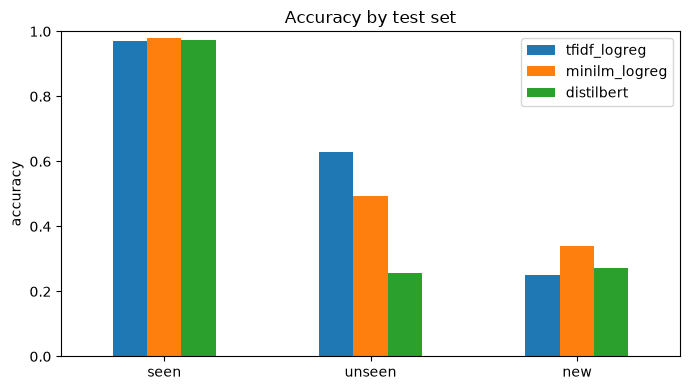

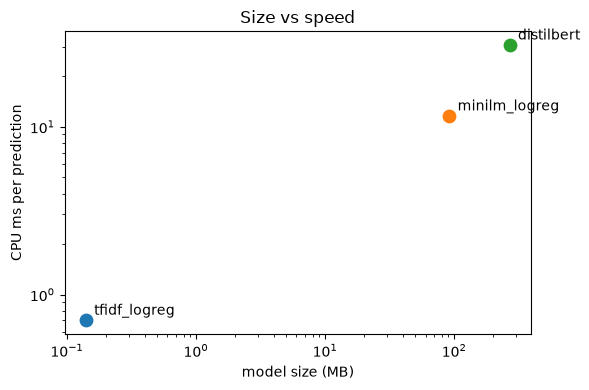

{
 "tfidf_logreg": {
  "seen": {
   "accuracy": 0.971,
   "macro_f1": 0.7919
  },
  "unseen": {
   "accuracy": 0.6296,
   "macro_f1": 0.3336
  },
  "new": {
   "accuracy": 0.25,
   "macro_f1": 0.1613
  }
 },
 "minilm_logreg": {
  "seen": {
   "accuracy": 0.9783,
   "macro_f1": 0.8966
  },
  "unseen": {
   "accuracy": 0.4949,
   "macro_f1": 0.2264
  },
  "new": {
   "accuracy": 0.3409,
   "macro_f1": 0.2183
  }
 },
 "distilbert": {
  "seen": {
   "accuracy": 0.9746,
   "macro_f1": 0.7956
  },
  "unseen": {
   "accuracy": 0.2559,
   "macro_f1": 0.1777
  },
  "new": {
   "accuracy": 0.2727,
   "macro_f1": 0.1816
  }
 }
}


In [15]:
results = {
    'models': {m: {'size_mb': sizes[m], 'latency_ms': latency[m], 'train_s': train_s[m]} for m in MODELS},
    'scores': {m: {t: score({'seen': seen_test, 'unseen': unseen_test, 'new': new}[t]['Category'], predictions[(m, t)])
                   for t in ['seen', 'unseen', 'new']} for m in MODELS},
    'rows': {'seen_train': len(seen_train), 'seen_test': len(seen_test), 'unseen_train': len(unseen_train),
             'unseen_test': len(unseen_test), 'new': len(new)},
}
Path('../blog/figures').mkdir(parents=True, exist_ok=True)
Path('../blog/results.json').write_text(json.dumps(results, indent=1))

acc = pd.DataFrame({m: {t: results['scores'][m][t]['accuracy'] for t in ['seen', 'unseen', 'new']} for m in MODELS})
ax = acc.plot.bar(rot=0, ylim=(0, 1), figsize=(7, 4), title='Accuracy by test set')
ax.set_ylabel('accuracy'); plt.tight_layout(); plt.savefig('../blog/figures/accuracy.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
for m in MODELS:
    ax.scatter(sizes[m], latency[m], s=80); ax.annotate(m, (sizes[m], latency[m]), xytext=(6, 4), textcoords='offset points')
ax.set(xscale='log', yscale='log', xlabel='model size (MB)', ylabel='CPU ms per prediction', title='Size vs speed')
plt.tight_layout(); plt.savefig('../blog/figures/speed-size.png', dpi=150); plt.show()

assert all(results['scores'][m][t] for m in MODELS for t in ['seen', 'unseen', 'new'])
print(json.dumps(results['scores'], indent=1))

**Is it worth it?** For Spendify (one user, a free Vercel server, a suggestion chip that must feel instant), would you switch to the transformer? Use your numbers.

**Your answer:** No, I'd keep TF-IDF + logistic regression.

- **Accuracy barely changes on merchants the user already has.** On the seen test, DistilBERT gets 97.5% vs TF-IDF's 97.1%, one more correct description out of 276, and its macro F1 is the same (0.796 vs 0.792). MiniLM is the best here (97.8%, macro F1 0.897), so even the rare-category advantage doesn't need a fine-tuned transformer.
- **It's worse where a transformer should help most.** On merchants it never saw, DistilBERT drops to 25.6% (unseen) vs TF-IDF's 63.0%, and on brand-new merchants it gets 27.3% vs 25.0%. The best model on new merchants, MiniLM, still only gets 34.1%, so whatever model ships, the app has to treat a new merchant's category as a suggestion and learn from the user's correction.
- **It's far too big for a free Vercel server.** TF-IDF is 0.14 MB; DistilBERT is 268.57 MB (about 2,000× larger) and MiniLM 91.61 MB, and both also need PyTorch, which is several hundred MB more. That likely won't fit a free serverless function, and if it did, every cold start would load all of it.
- **It isn't instant.** On one CPU thread, TF-IDF takes 0.70 ms per description, MiniLM 11.6 ms and DistilBERT 30.7 ms (about 40× slower), before any cold start. A suggestion chip shown while typing needs the TF-IDF speed.
- **Retraining:** DistilBERT took 6.8 s to train on the GPU vs 0.1 s for TF-IDF. For one user, TF-IDF can retrain after every correction on a free CPU server; DistilBERT can't.

For one user, a free server and an instant chip, the small model wins on every practical measure, and the transformer doesn't even buy accuracy on this data. I'd revisit it only with many users, a GPU server, and evidence that it actually handles new merchants better.